In [1]:
%pip install tifffile
import numpy as np
import pandas as pd
import tifffile


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATASET_ROOT = PROJECT_ROOT.parent / "datasets" / "SmokeViz"

from pathlib import Path

DATA_DIR = Path(r"C:\Users\Amin\Desktop\Applied\Project\sample_data") / "data"
COORDS_DIR = Path(r"C:\Users\Amin\Desktop\Applied\Project\sample_data") / "coords"
METADATA_PATH = Path(r"C:\Users\Amin\Desktop\Applied\Project\sample_data") / "subsample.pkl"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)

assert DATA_DIR.exists(), f"Data directory not found: {DATA_DIR}"
assert COORDS_DIR.exists(), f"Coords directory not found: {COORDS_DIR}"
assert METADATA_PATH.exists(), f"Metadata file not found: {METADATA_PATH}"

print("Dataset root:", DATASET_ROOT)
print("Data exists:", DATA_DIR.exists())
print("Coords exists:", COORDS_DIR.exists())
print("Metadata exists:", METADATA_PATH.exists())

Project: c:\Users\Amin\Desktop\Applied\2026-P14-LINKS_ADSP-Wildfire_Smoke_Segmentation
Dataset: c:\Users\Amin\Desktop\Applied\datasets\SmokeViz
Dataset root: c:\Users\Amin\Desktop\Applied\datasets\SmokeViz
Data exists: True
Coords exists: True
Metadata exists: True


In [3]:
print("Data years:")
print([folder.name for folder in DATA_DIR.iterdir() if folder.is_dir()])

print("\nCoordinate years:")
print([folder.name for folder in COORDS_DIR.iterdir() if folder.is_dir()])

Data years:
['2020', '2021', '2022', '2023']

Coordinate years:
['2020', '2021', '2022', '2023']


In [4]:
YEARS = ["2021", "2022", "2023"]
CLASSES = ["none", "light", "medium", "heavy"]

rows = []

for year in YEARS:
    for smoke_class in CLASSES:

        data_folder = DATA_DIR / year / smoke_class
        coords_folder = COORDS_DIR / year / smoke_class

        data_files = sorted(
            list(data_folder.glob("*.tif"))
            + list(data_folder.glob("*.tiff"))
        )

        coords_files = sorted(
            list(coords_folder.glob("*.tif"))
            + list(coords_folder.glob("*.tiff"))
        )

        # DATA row
        if data_files:
            data_array = tifffile.imread(data_files[0])

            rows.append({
                "year": year,
                "class": smoke_class,
                "file_root": "data",
                "folder": str(data_folder),
                "number_of_files": len(data_files),
                "shape": str(data_array.shape),
                "dtype": str(data_array.dtype),
                "min_value": float(np.nanmin(data_array)),
                "max_value": float(np.nanmax(data_array))
            })

        # COORDS row
        if coords_files:
            coords_array = tifffile.imread(coords_files[0])

            rows.append({
                "year": year,
                "class": smoke_class,
                "file_root": "coords",
                "folder": str(coords_folder),
                "number_of_files": len(coords_files),
                "shape": str(coords_array.shape),
                "dtype": str(coords_array.dtype),
                "min_value": float(np.nanmin(coords_array)),
                "max_value": float(np.nanmax(coords_array))
            })

audit_df = pd.DataFrame(rows)

audit_df

,year,class,file_root,folder,number_of_files,shape,dtype,min_value,max_value
0,2021,none,data,C:\Users\Amin\Desktop\Applied\Project\sample_d...,122,"(256, 256, 3)",float64,0.053719,0.893004
1,2021,none,coords,C:\Users\Amin\Desktop\Applied\Project\sample_d...,122,"(256, 256, 2)",float64,-106.563222,30.446580
2,2021,light,data,C:\Users\Amin\Desktop\Applied\Project\sample_d...,93,"(256, 256, 3)",float64,0.000000,1.000000
3,2021,light,coords,C:\Users\Amin\Desktop\Applied\Project\sample_d...,93,"(256, 256, 2)",float64,-99.646509,20.622501
4,2021,medium,data,C:\Users\Amin\Desktop\Applied\Project\sample_d...,38,"(256, 256, 3)",float64,0.000000,1.000000
5,2021,medium,coords,C:\Users\Amin\Desktop\Applied\Project\sample_d...,38,"(256, 256, 2)",float64,-114.354643,32.432284
6,2021,heavy,data,C:\Users\Amin\Desktop\Applied\Project\sample_d...,25,"(256, 256, 3)",float64,0.035874,0.968627
7,2021,heavy,coords,C:\Users\Amin\Desktop\Applied\Project\sample_d...,25,"(256, 256, 2)",float64,-99.018151,47.187693
8,2022,none,data,C:\Users\Amin\Desktop\Applied\Project\sample_d...,88,"(256, 256, 3)",float64,0.000000,0.904192
9,2022,none,coords,C:\Users\Amin\Desktop\Applied\Project\sample_d...,88,"(256, 256, 2)",float64,-104.283800,31.980421


In [5]:
import pickle

with open(METADATA_PATH, "rb") as file:
    metadata = pickle.load(file)

print("Object type:", type(metadata))

if isinstance(metadata, pd.DataFrame):
    print("Shape:", metadata.shape)
    print("Columns:", metadata.columns.tolist())
    display(metadata.head())

elif isinstance(metadata, dict):
    print("Keys:", metadata.keys())

    for key, value in metadata.items():
        print(
            key,
            "->",
            type(value),
            getattr(value, "shape", None)
        )

elif isinstance(metadata, (list, tuple)):
    print("Length:", len(metadata))
    print("First item:", metadata[0])

Object type: <class 'dict'>
Keys: dict_keys(['train', 'val', 'test'])
train -> <class 'dict'> None
val -> <class 'dict'> None
test -> <class 'dict'> None


In [6]:
if isinstance(metadata, pd.DataFrame):

    keywords = [
        "label",
        "class",
        "density",
        "smoke",
        "mask",
        "polygon",
        "year",
        "date",
        "time",
        "split",
        "file",
        "path",
    ]

    matching_columns = [
        column
        for column in metadata.columns
        if any(
            keyword in str(column).lower()
            for keyword in keywords
        )
    ]

    print("Relevant columns:")
    print(matching_columns)

    display(metadata[matching_columns].head())

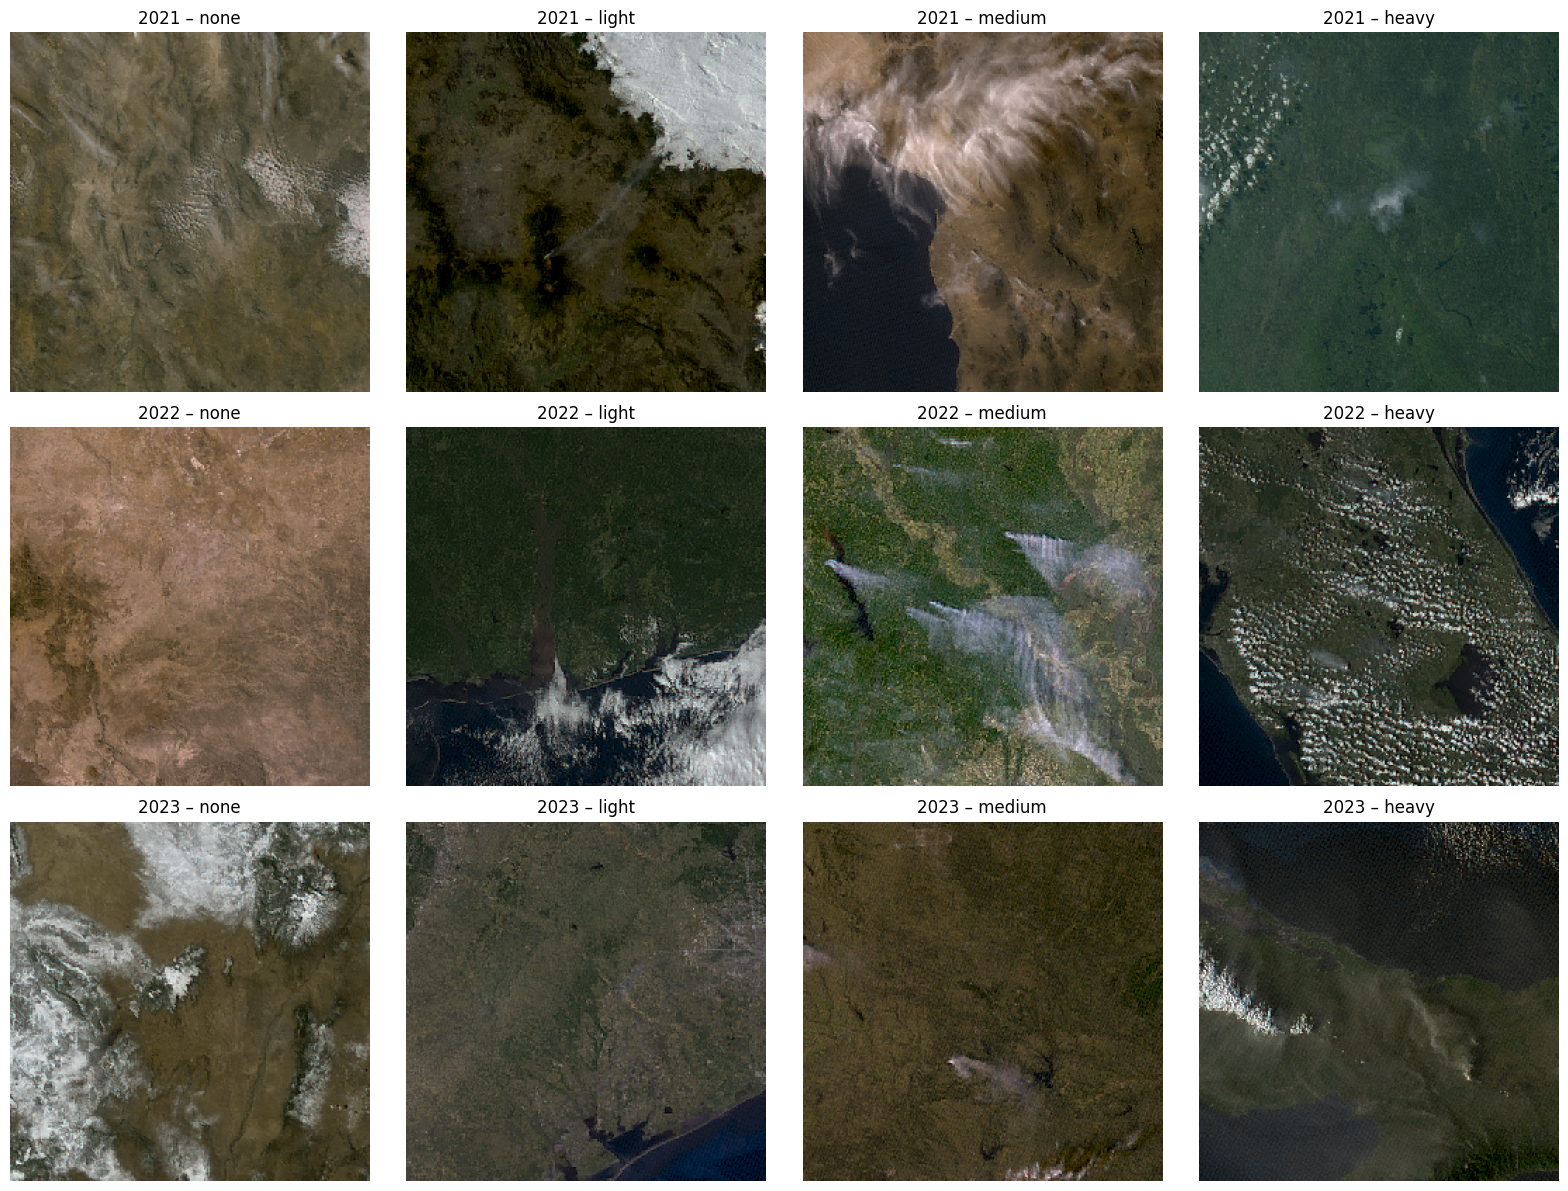

In [7]:
import matplotlib.pyplot as plt
import tifffile
import numpy as np

fig, axes = plt.subplots(
    len(YEARS),
    len(CLASSES),
    figsize=(16, 12)
)

for row_index, year in enumerate(YEARS):
    for column_index, smoke_class in enumerate(CLASSES):

        folder = DATA_DIR / year / smoke_class

        files = sorted(
            list(folder.glob("*.tif"))
            + list(folder.glob("*.tiff"))
        )

        image = tifffile.imread(files[0])

        image = np.clip(image, 0, 1)

        axes[row_index, column_index].imshow(image)
        axes[row_index, column_index].set_title(
            f"{year} – {smoke_class}"
        )
        axes[row_index, column_index].axis("off")

plt.tight_layout()
plt.show()

In [8]:
for split_name, split_data in metadata.items():

    print("\n" + "=" * 60)
    print("SPLIT:", split_name)
    print("Type:", type(split_data))

    if isinstance(split_data, dict):
        print("Keys:", split_data.keys())

        for key, value in split_data.items():
            print(
                f"  {key}:",
                "type =", type(value),
                "length =", len(value) if hasattr(value, "__len__") else None,
                "shape =", getattr(value, "shape", None)
            )


SPLIT: train
Type: <class 'dict'>
Keys: dict_keys(['truth', 'data'])
  truth: type = <class 'list'> length = 1000 shape = None
  data: type = <class 'list'> length = 1000 shape = None

SPLIT: val
Type: <class 'dict'>
Keys: dict_keys(['truth', 'data'])
  truth: type = <class 'list'> length = 99 shape = None
  data: type = <class 'list'> length = 99 shape = None

SPLIT: test
Type: <class 'dict'>
Keys: dict_keys(['truth', 'data'])
  truth: type = <class 'list'> length = 99 shape = None
  data: type = <class 'list'> length = 99 shape = None


In [9]:
for split_name, split_data in metadata.items():

    print("\n" + "=" * 60)
    print("SPLIT:", split_name)

    for key, value in split_data.items():

        print(f"\nKEY: {key}")
        print("Type:", type(value))

        if isinstance(value, dict):
            print("Nested keys:", list(value.keys())[:10])

        elif isinstance(value, (list, tuple, np.ndarray)):
            print("First values:", value[:5])

        elif isinstance(value, pd.DataFrame):
            display(value.head())

        else:
            print("Value:", value)


SPLIT: train

KEY: truth
Type: <class 'list'>
First values: [1, 1, 1, 1, 1]

KEY: data
Type: <class 'list'>
First values: ['/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20201392310151_e20201392319459_90.tif', '/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20200932230207_e20200932239515_225.tif', '/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20200552300186_e20200552309494_293.tif', '/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20201112210163_e20201112219471_16.tif', '/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20202822330181_e20202822339489_67.tif']

SPLIT: val

KEY: truth
Type: <class 'list'>
First values: [1, 1, 1, 1, 1]

KEY: data
Type: <class 'list'>
First values: ['/scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2022/Light/G16_s20220062100208_e20220062109516

In [10]:
def show_structure(obj, name="metadata", level=0, max_items=5):

    indent = "    " * level

    if isinstance(obj, dict):
        print(
            f"{indent}{name}: dict with {len(obj)} keys"
        )

        for key, value in list(obj.items())[:max_items]:
            show_structure(
                value,
                name=str(key),
                level=level + 1,
                max_items=max_items
            )

    elif isinstance(obj, pd.DataFrame):
        print(
            f"{indent}{name}: DataFrame "
            f"shape={obj.shape}, "
            f"columns={obj.columns.tolist()}"
        )

    elif isinstance(obj, np.ndarray):
        print(
            f"{indent}{name}: NumPy array "
            f"shape={obj.shape}, dtype={obj.dtype}"
        )

        print(
            f"{indent}    first values:",
            obj.flatten()[:5]
        )

    elif isinstance(obj, (list, tuple)):
        print(
            f"{indent}{name}: {type(obj).__name__} "
            f"length={len(obj)}"
        )

        if len(obj) > 0:
            print(
                f"{indent}    first item:",
                obj[0]
            )

    else:
        print(
            f"{indent}{name}: "
            f"{type(obj).__name__} = {obj}"
        )


show_structure(metadata)

metadata: dict with 3 keys
    train: dict with 2 keys
        truth: list length=1000
            first item: 1
        data: list length=1000
            first item: /scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2020/Light/G16_s20201392310151_e20201392319459_90.tif
    val: dict with 2 keys
        truth: list length=99
            first item: 1
        data: list length=99
            first item: /scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2022/Light/G16_s20220062100208_e20220062109516_93.tif
    test: dict with 2 keys
        truth: list length=99
            first item: 1
        data: list length=99
            first item: /scratch/alpine/mecr8410/semantic_segmentation_smoke/sample_data/data/2022/Light/G16_s20220151900205_e20220151909513_15.tif


In [11]:
from pathlib import Path

original_path = Path(
    metadata["train"]["data"][0]
)

filename = original_path.name
year = original_path.parts[-3]
smoke_class = original_path.parts[-2]

local_path = (
    DATA_DIR
    / year
    / smoke_class.lower()
    / filename
)

print("Original path:", original_path)
print("Local path:", local_path)
print("Local file exists:", local_path.exists())

Original path: \scratch\alpine\mecr8410\semantic_segmentation_smoke\sample_data\data\2020\Light\G16_s20201392310151_e20201392319459_90.tif
Local path: C:\Users\Amin\Desktop\Applied\Project\sample_data\data\2020\light\G16_s20201392310151_e20201392319459_90.tif
Local file exists: True


In [12]:
import pandas as pd
from pathlib import Path

mapping_rows = []

for split_name in ["train", "val", "test"]:

    paths = metadata[split_name]["data"]
    labels = metadata[split_name]["truth"]

    for original_path, label in zip(paths, labels):

        original_path = Path(original_path)

        mapping_rows.append({
            "split": split_name,
            "label": label,
            "folder_class": original_path.parts[-2],
            "year": original_path.parts[-3],
            "filename": original_path.name,
        })

mapping_df = pd.DataFrame(mapping_rows)

label_mapping = (
    mapping_df[
        ["label", "folder_class"]
    ]
    .drop_duplicates()
    .sort_values("label")
)

display(label_mapping)

,label,folder_class
243,0,None
0,1,Light
172,1,Medium
221,1,Heavy


In [14]:
consistency = pd.crosstab(
    mapping_df["label"],
    mapping_df["folder_class"]
)

display(consistency)

folder_class,Heavy,Light,Medium,None
label,,,,
0,0,0,0,580
1,86,377,155,0


In [15]:
class_counts = pd.crosstab(
    mapping_df["split"],
    mapping_df["folder_class"],
    margins=True
)

display(class_counts)

folder_class,Heavy,Light,Medium,None,All
split,,,,,
test,11,31,20,37,99
train,69,319,120,492,1000
val,6,27,15,51,99
All,86,377,155,580,1198


In [16]:
local_years = sorted([
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

print("Local years:", local_years)

Local years: ['2020', '2021', '2022', '2023']


In [17]:
def convert_to_local_path(original_path):

    original_path = Path(original_path)

    year = original_path.parts[-3]
    smoke_class = original_path.parts[-2].lower()
    filename = original_path.name

    return DATA_DIR / year / smoke_class / filename


path_check_rows = []

for split_name in ["train", "val", "test"]:

    for original_path in metadata[split_name]["data"]:

        local_path = convert_to_local_path(original_path)

        path_check_rows.append({
            "split": split_name,
            "original_path": original_path,
            "local_path": str(local_path),
            "exists": local_path.exists(),
        })

path_check_df = pd.DataFrame(path_check_rows)

display(
    path_check_df
    .groupby("split")["exists"]
    .agg(["count", "sum"])
    .rename(columns={
        "count": "metadata_samples",
        "sum": "local_files_found"
    })
)

,metadata_samples,local_files_found
split,,
test,99,99
train,1000,1000
val,99,99
